# Wombloom: using 7,955 app reviews to decide what to build first

**A product research case study.** When I was pregnant I wanted one place to keep the whole journey, so I designed Wombloom, a private pregnancy and baby journal for iPhone. Before deciding what it should do first, I wanted evidence beyond my own experience. This notebook shows how I got it, what I found, and where the evidence disagreed with me.

**Results at a glance**
- **Trust problems cost competitors the most stars.** Reviews that mention ads, updates or bugs average 2.4 to 2.6 stars, against 4.16 for all reviews.
- **Pricing is the most discussed pain point.** 20% of reviews mention it, and 36.5% of those give 1 or 2 stars.
- **Journaling is the clearest opening, but a thin one.** Reviews of journal-style apps talk about memories about 9 times as often as reviews of the other apps. Most of that comes from two apps.
- **The ranking is stable where it matters.** Pricing, updates and ads stay in the top three in 84% to 99% of 5,000 random weightings of my priority model.
- **My own plan held up on trust and missed one thing.** Wombloom v1.0 has no ads, no account and collects no data, but entries live only on the phone, which is exactly the failure reviewers punish most.

**Read more:** [interactive dashboard](../dashboard/README.md) | [full working notebook](appendix_working_notebook.ipynb) | [research plan written before data collection](../docs/research_plan.md)

This notebook runs from the aggregated files in `data/aggregates/`. The review text itself is not published.

**Contents:** 1. The problem · 2. Method · 3. Choosing competitors · 4. The data and its limits · 5. Reading the reviews · 6. Complaints and praise · 7. Where the gap is · 8. From findings to priorities · 9. Checking my own plan · 10. Recommendations · 11. Measuring success · 12. Reflection

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import report  # loading and chart functions for this notebook

data = report.load(ROOT)
report.style()

## 1. The problem I started with

During my pregnancy, my photos were scattered across my camera roll, checkup dates sat in one place, insurance checks in another, and the shopping list somewhere else. I wrote down everything I needed and grouped it:

- **Remember:** a journal and the photos that go with it
- **Plan:** checkups, appointments and insurance checks
- **Prepare:** a shopping list and a budget

That list became the first plan for Wombloom. It was also a hypothesis, not evidence. One user is not a market, and I knew what I wanted before I knew what other parents wanted. So before committing to an order of features, I set three questions:

1. What do parents praise and complain about in the apps they already use?
2. Where do existing apps leave a gap that a journal could fill?
3. Given that, what should Wombloom build first, and how sure can I be?

**Why app reviews?** They are public, there are thousands of them, and they come from people who have actually used these apps. They are also self-selected (people with strong feelings write more), and they describe other apps' users, not mine. I chose them knowing those limits and planned around them.

## 2. Method

I wrote the research plan before collecting anything ([docs/research_plan.md](../docs/research_plan.md)), with a review checkpoint at each step.

| Step | What I did | The choice that mattered |
|---|---|---|
| Scope | iOS App Store, US and Canada, English reviews | Wombloom launches on iOS. I later dropped Google Play: the iOS sample was enough for exploratory work |
| Competitors | 20 keyword searches, documented filters, 10 apps in three groups | A repeatable selection, not apps picked from memory |
| Collection | Apple's public review feed, the newest 500 reviews per app and country | Polite request rates. No reviewer names or IDs stored |
| Cleaning | Duplicates removed, language detected, very short reviews flagged | Nothing else deleted, so later steps can decide what to exclude |
| Reading reviews | 19 keyword-based topics, tested against 150 labeled reviews | Only topics that held up on held-out reviews are treated as measurements |
| Deciding | A scoring model, stress-tested with 5,000 random weightings, plus a second lens for differentiation | Weights are assumptions, so I tested which conclusions survive them |
| Checking | The findings compared with what Wombloom v1.0 actually contains | The honest test of my own plan |

## 3. Choosing competitors

I did not want to pick competitors from memory, so the selection had to be repeatable. Twenty App Store searches in the US and Canada ("pregnancy tracker", "pregnancy journal", "baby tracker", "postpartum" and others) returned 1,464 unique apps. Each filter was applied in a fixed order, and I recorded what it removed.

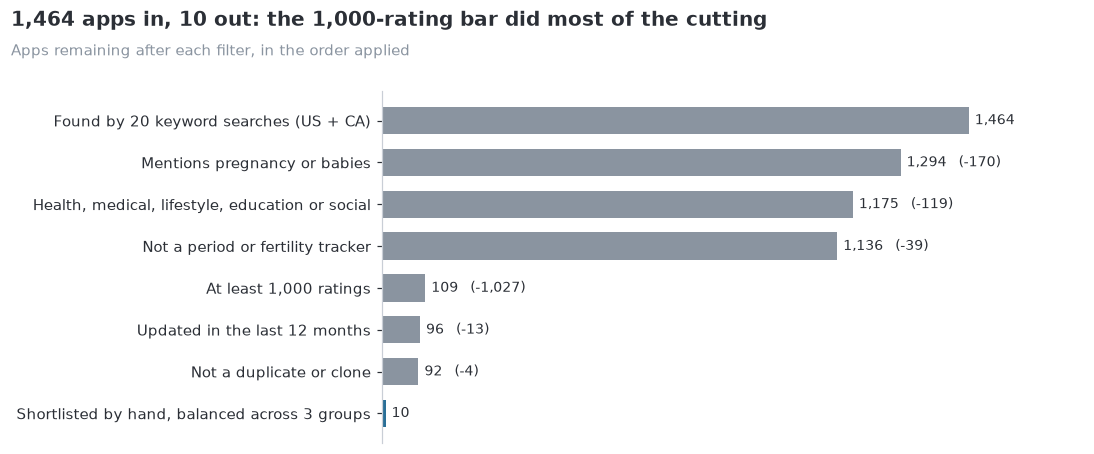

In [2]:
report.funnel(data)

Two judgment calls are worth stating:

- **I excluded period and fertility trackers** (Flo, Clue and similar). They appear in pregnancy searches but are a different product, and they would have crowded out the apps that matter.
- **I relaxed the 1,000-rating bar for one journal app** (280days, about 480 ratings). The apps closest to Wombloom's idea are small, and leaving them all out would have left nothing to compare with. I flagged it as a weak sample.

The final ten are balanced across three groups. From here on I call them **journal apps** (memory keeping, the closest to Wombloom), **pregnancy leaders** (the big week-by-week trackers) and **baby trackers** (where parents go after the birth).

In [3]:
report.show(report.shortlist_table(data), precision=0)

Group,App,Developer,Store ratings,Reviews collected,Usable for text analysis
Journal apps,Qeepsake: Family Photo Album,Tinybeans USA Ltd.,"14,630",586,573
Journal apps,Cubtale: Pregnancy & Baby,Cubtale,"7,403",331,322
Journal apps,280days: Pregnancy Diary App,amane factory inc.,482,119,94
Pregnancy leaders,Pregnancy Tracker App - WTE,"Everyday Health, Inc.","380,433","1,000",844
Pregnancy leaders,Pregnancy + | Tracker App,Philips Digital UK Limited,"76,780","1,000",698
Pregnancy leaders,The Bump: Pregnancy & Baby App,The Knot Inc.,"40,161","1,000",921
Pregnancy leaders,Nurture Pregnancy Week by Week,Glow,"30,266",919,758
Baby trackers,Baby Tracker - Newborn Log,Nighp Software LLC,"227,368","1,000",916
Baby trackers,Huckleberry: Baby Tracker,Huckleberry Labs Inc.,"75,363","1,000",966
Baby trackers,Glow Baby Tracker & Growth App,Glow,"23,465","1,000",932


One correction came later. Only Qeepsake is really a memory-keeping app. Cubtale behaves like a tracker (75% of its reviews are about tracking), and 280days has few reviews. I kept the "journal apps" group, but I read it as three different cases rather than one market.

## 4. The data, and how far to trust it

Apple's feed returns only the newest 500 reviews per app and country, so "all reviews" means very different things for different apps:

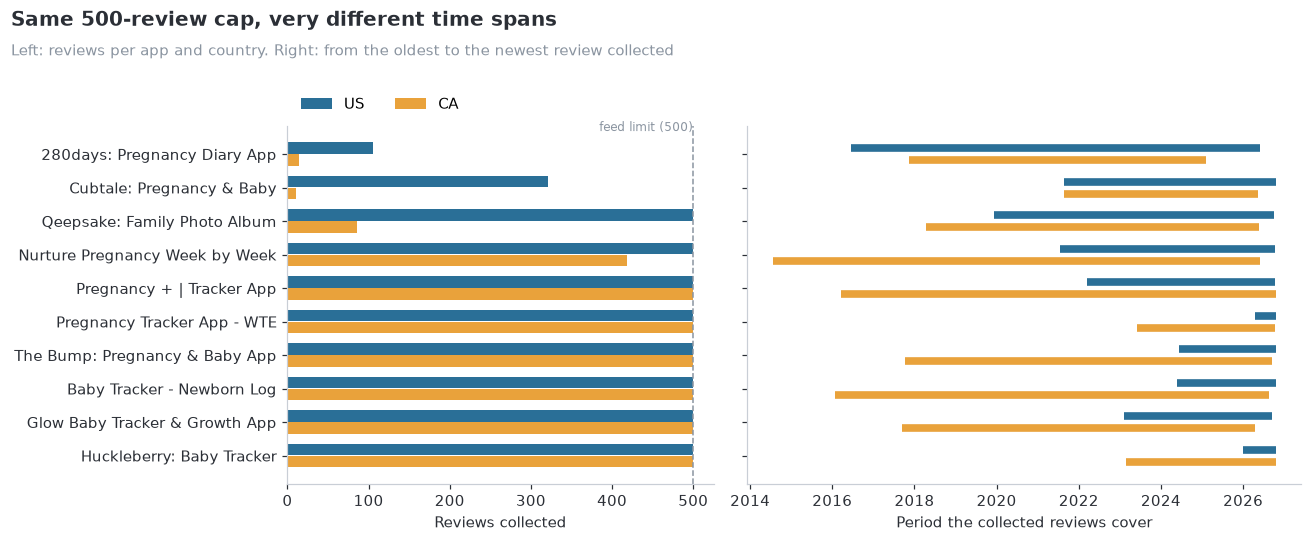

In [4]:
report.coverage(data)

For What to Expect in the US, 500 reviews cover about six months. For Nurture in Canada they cover almost 12 years. Comparing apps on raw totals would mix old and new versions of the same app. So **every comparison in this study is run twice**: on all reviews, and on the last 24 months only (for apps with at least 30 reviews in that window). I only report a pattern when both views agree, or I say that they don't.

The sample also leans heavily recent:

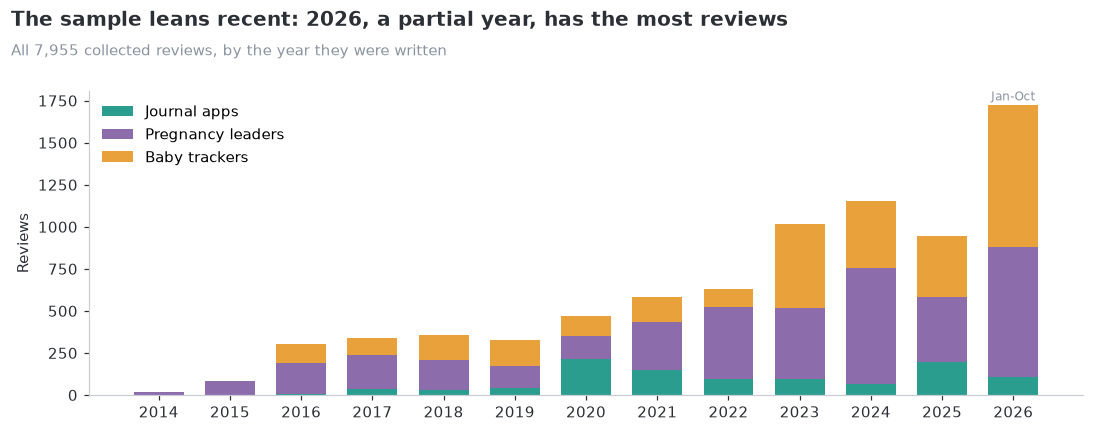

In [5]:
report.recency(data)

**Quality.** Of 7,955 reviews, none were duplicates. 7,024 (88%) are in English and at least five words long, which is the set I analyze. Pregnancy+ loses the most (70% usable), mostly because of French reviews from Canada. About a quarter of the usable reviews were written in the final 12 months of the data.

In [6]:
report.show(report.quality_table(data))

Group,App,Reviews,Usable,Under 5 words,Not English or undetermined,% usable
Journal apps,280days: Pregnancy Diary App,119,94,1,24,79.0
Journal apps,Cubtale: Pregnancy & Baby,331,322,0,9,97.3
Journal apps,Qeepsake: Family Photo Album,586,573,5,8,97.8
Pregnancy leaders,Pregnancy + | Tracker App,"1,000",698,8,294,69.8
Pregnancy leaders,Nurture Pregnancy Week by Week,919,758,19,142,82.5
Pregnancy leaders,Pregnancy Tracker App - WTE,"1,000",844,17,139,84.4
Pregnancy leaders,The Bump: Pregnancy & Baby App,"1,000",921,18,61,92.1
Baby trackers,Baby Tracker - Newborn Log,"1,000",916,1,83,91.6
Baby trackers,Glow Baby Tracker & Growth App,"1,000",932,6,62,93.2
Baby trackers,Huckleberry: Baby Tracker,"1,000",966,6,28,96.6


**One problem almost slipped through.** The first collection run recorded zero US reviews for What to Expect, an app with about 380,000 ratings. The feed had returned an empty page once, and the script read it as "no more reviews". A coverage check at the review checkpoint caught it. The collector now re-checks an empty page before treating it as the end.

## 5. Reading 7,000 reviews: what I tried and what I trusted

My first instinct was an off-the-shelf sentiment tool (VADER). Before relying on it, I checked it against the one ground truth I had, the star rating each reviewer gave:

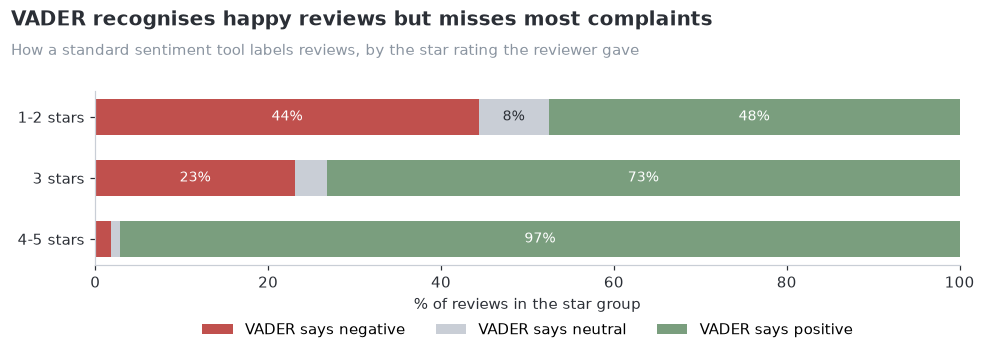

In [7]:
report.vader_vs_stars(data)

VADER labels 97% of 4-5 star reviews positive, but only 44% of 1-2 star reviews negative. Complaints are often polite or mixed ("Love the app, but..."), and VADER reads the politeness. So I used **the star rating for direction** and the text only for **what a review is about**.

For that, I read about 100 reviews, wrote a codebook (it settled at 19 topics), and turned each topic into keyword rules. A topic is something a review discusses, not a verdict: "pricing" covers both "worth every penny" and "a scam". To know how far to trust the rules, 150 reviews were labeled and split in two. I tuned the rules on 100 and scored them once on the other 50.

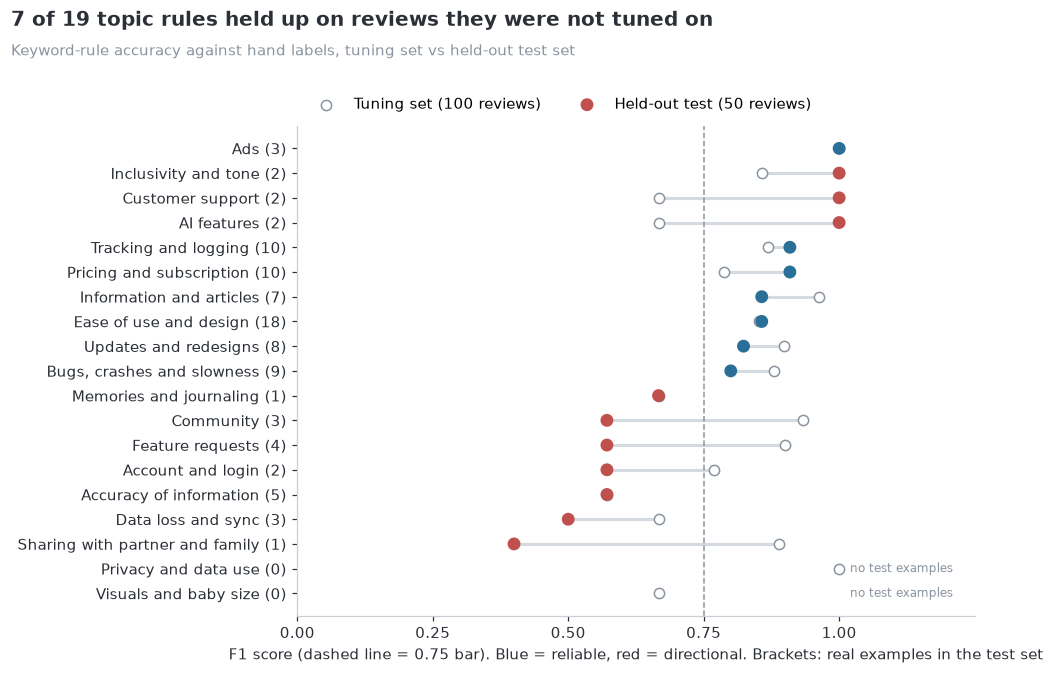

In [8]:
report.rule_accuracy(data)

Seven topics passed (an F1 score of at least 0.75, with at least three real examples in the test set): ads, pricing, updates, bugs, information, tracking, and ease of use. Their average test F1 is 0.88. The other twelve were too rare to test or scored below the bar. I treat them as **leads, not measurements**, and every chart from here colours them red.

Two things I want to be upfront about. The rules scored higher on the reviews they were tuned on than on the held-out ones, which is why only held-out scores count. And the 150 labels were made with AI assistance, not by a second person, so the scores measure agreement with those labels rather than with an independent judge. That is the weakest link in the method, and section 12 explains how I would close it.

## 6. What reviewers complain about, and what they value

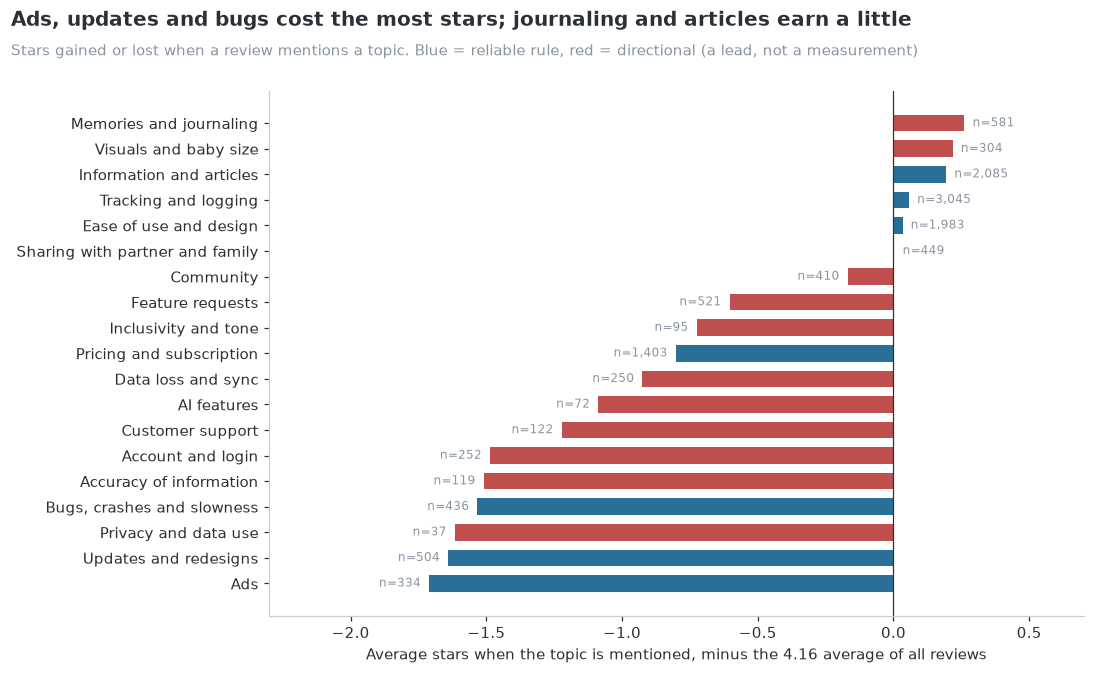

In [9]:
report.topic_impact(data)

Among the reliable topics, **ads, updates and bugs** cost the most: reviews that mention them sit 1.5 to 1.7 stars below average. **Pricing** costs less per review (about 0.8 stars), but it is the most discussed: 20% of all reviews, rising to 23% in the last 24 months.

The positive side is small. Information, journaling and visuals sit only 0.2 to 0.3 stars above average, because most reviews are already five stars. That asymmetry shapes everything after this: getting a basic thing wrong costs far more than excelling at a nice-to-have earns.

## 7. Where the gap is

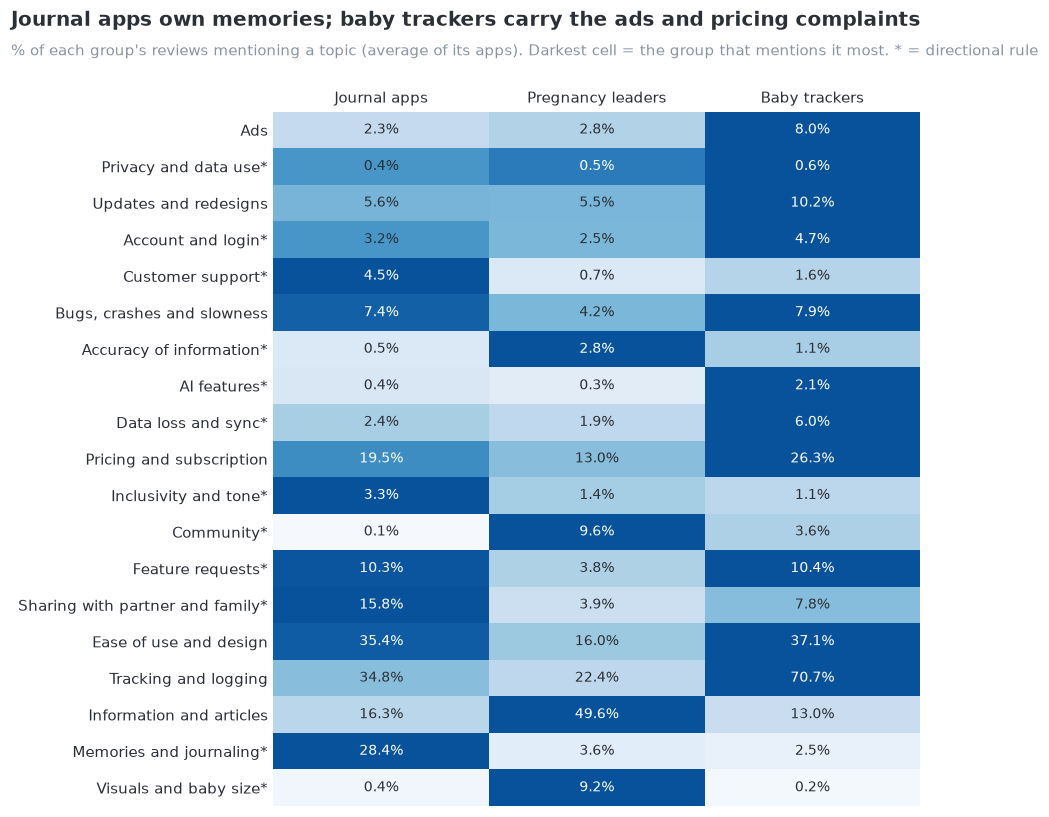

In [10]:
report.segment_heatmap(data)

Each group has a different conversation:

- **Pregnancy leaders** are about information: 50% of their reviews mention articles and week-by-week content.
- **Baby trackers** are about tracking (71%), and they carry the complaints: ads in 8.0% of reviews against 2 to 3% elsewhere, pricing in 26%, and updates in 10%. In the last 24 months, ads rose to 12.9%.
- **Journal apps** are where memories come up: 28% of their reviews against under 4% for the others (40% in the last 24 months). Sharing with a partner or family is also highest here (16%).

This looked like Wombloom's opening. The big apps barely touch journaling, and people who write about it are happy (4.4 stars). Two caveats keep me careful: "memories" is a directional topic, and the 28% comes mostly from Qeepsake (65% of its reviews).

## 8. From findings to priorities

I turned the findings into 15 candidate actions. Ranking them by gut would have undone the work, so I scored them:

**score = reach + impact + confidence - effort**

- **Reach:** the share of reviews that mention the topic, averaged per app so the big apps don't dominate.
- **Impact:** stars at stake, meaning how far the average rating of those reviews sits from the overall average.
- **Confidence:** 1.0 for a reliable topic, and less for directional ones with few mentions.
- **Effort:** my estimate, from 1 to 3.

The weights are my assumptions, so I redrew them at random 5,000 times and watched where each action landed:

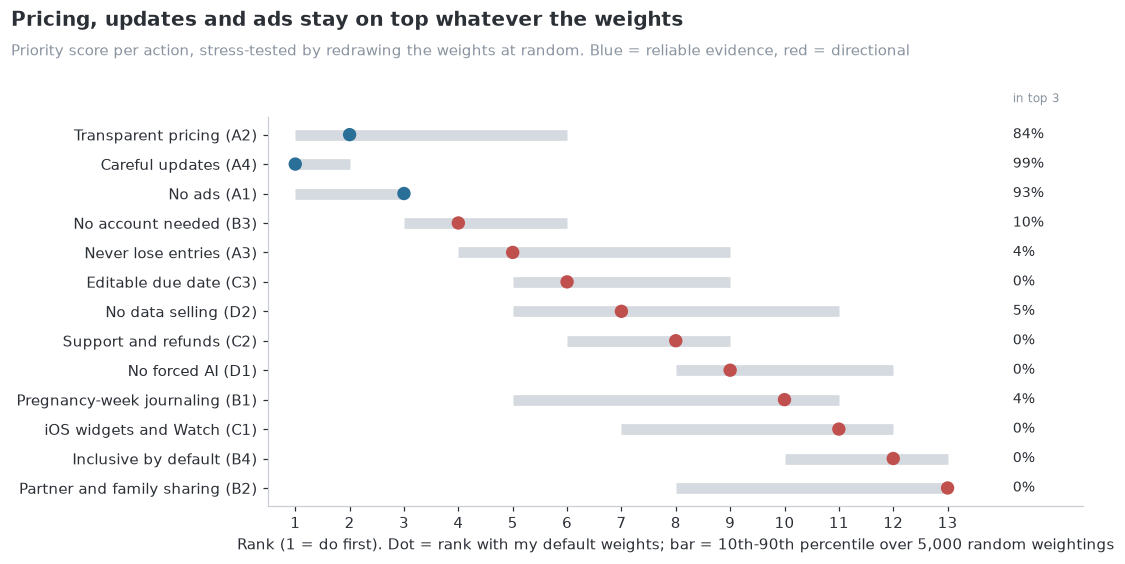

In [11]:
report.priority_stability(data)

Pricing, updates and ads are in the top three in 84% to 99% of weightings. The same five actions make the top five whether I use all reviews, only the last 24 months, or ignore effort entirely. That is the most defensible conclusion in this project.

**The model also disagreed with me.** I had ranked pregnancy-week journaling fifth. The model puts it tenth, and partner sharing last. I did not tune the model until it agreed. Instead I asked why. The score measures what it costs to get a topic wrong, and nobody is unhappy about journaling. What it cannot see is whether a topic is a chance to stand out. So I added a second lens, which asks how much more the journal apps talk about a topic than everyone else:

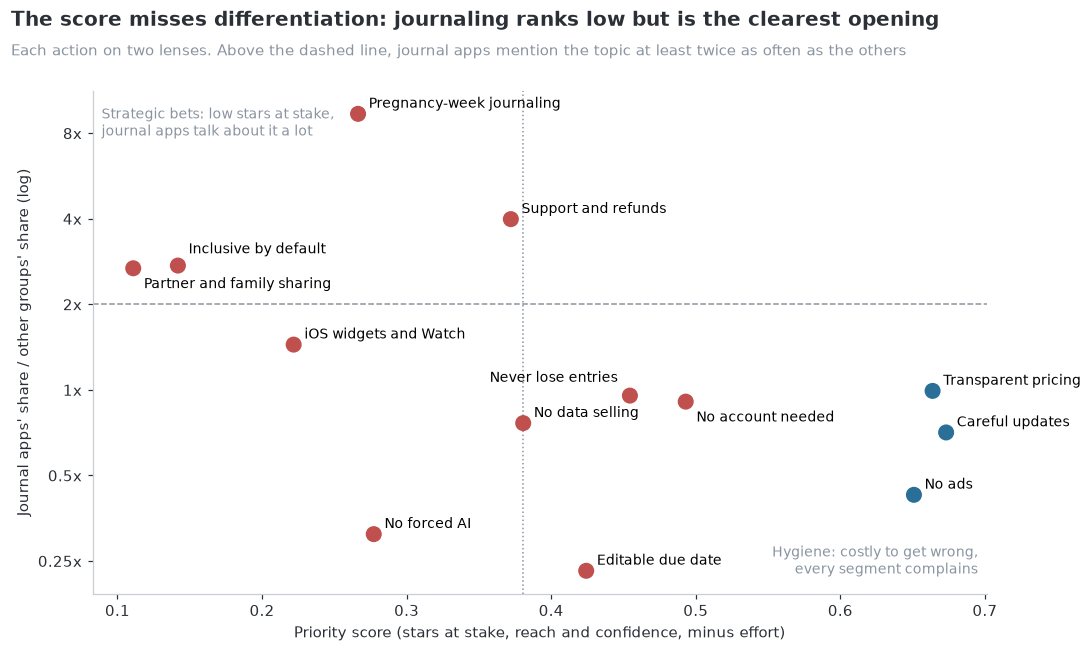

In [12]:
report.two_lenses(data)

Read together, the two lenses give two kinds of priority:

- **Hygiene (bottom right):** pricing, updates, ads, account-free use and data safety. They are costly to get wrong, every group complains about them, and the evidence is the strongest I have.
- **A strategic bet (top left):** pregnancy-week journaling. It over-indexes about 9 times in journal apps, but it rests on two apps. It is worth testing before building heavily.

Sharing and inclusivity also look like openings over all reviews (2.7 times), but drop to 1.4 times in the last 24 months, so they wait.

In [13]:
report.show(report.actions_table(data))

ID,Action,Priority,Evidence,Model rank,Journal-app index,Wombloom v1.0
A1,No ads,P0,Strong,3,0.4x,Shipped
A2,Transparent pricing,P0,Strong,2,1.0x,Not applicable yet
A3,Never lose entries,P0,Moderate,5,1.0x,Missing
A4,Careful updates,P0,Strong,1,0.7x,Not applicable yet
B1,Pregnancy-week journaling,P1,Moderate,10,9.4x,Partial
B2,Partner and family sharing,P1,Moderate,13,2.7x,Missing
B3,No account needed,P1,Moderate,4,0.9x,Shipped
B4,Inclusive by default,P1,Exploratory,12,2.7x,Partial
B5,Honest keepsakes,P1,Exploratory,,,Missing
C1,iOS widgets and Watch,P2,Moderate,11,1.4x,Missing


## 9. Checking my own plan against the evidence

My feature list came before this research. The fair test is to compare what I planned with what the evidence says.

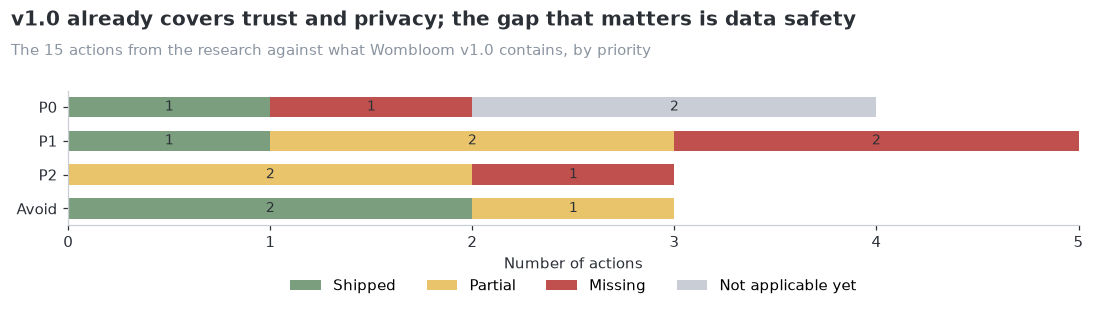

In [14]:
report.plan_vs_reality(data)

- **What held up:** no ads, no account, no AI and no data collected. These avoid several of the lowest-rated topics in competitors' reviews, by design.
- **The gap:** **backup and export.** Entries and photos live only on the phone, and deleting the app deletes them. It is the only top-priority action Wombloom v1.0 is missing, and reviewers of other apps describe exactly this failure: *"I was signed out for some reason today and now all of my pictures and journal entries are gone"* (The Bump, 2 stars).
- **Missing by design:** partner sharing. It needs accounts and a server, which conflicts with the privacy promise. Given its low ranking and fading signal, I am comfortable with that trade-off for now.
- **Partial:** journaling. v1.0 has daily journal pages with photos, but no pregnancy-week prompts. The evidence on prompts cuts both ways: Qeepsake users love them and also complain when they repeat or don't fit their stage. *"The questions obviously I couldn’t answer, and then after my baby was born the questions weren’t age appropriate"* (Qeepsake, 2 stars).

Wombloom also has features the research had no topic for. A quick keyword count in competitors' reviews:

In [15]:
report.show(report.feature_probe_table(data))

Feature in v1.0,Reviews mentioning,% of reviews,Avg stars,% 1-2 star
"Personalization (stickers, themes, cute design)",221,3.1,4.2,13.6
Reminders and notifications,149,2.1,3.5,30.2
Appointments and calendar,120,1.7,4.3,11.7
"Shopping list, registry or budget",47,0.7,3.7,23.4
Ultrasound or scan logging,22,0.3,3.2,36.4
Growth or weight charts,21,0.3,3.7,23.8
Other languages (including Vietnamese),15,0.2,2.5,46.7


The shopping list and budget, my own need, barely show up (0.7% of reviews). I don't read that as "cut it". Reviews can only mention what apps offer, so an absence is weak evidence. It is a question for my own users. Reminders are worth watching: 30% of reviews that mention them give 1 or 2 stars, against 17% overall, so they need to work reliably.

## 10. What I recommend

**Do first, before adding features**
1. **Backup and export**, so a lost phone or a deleted app never means lost memories.
2. **Decide the pricing model before charging for anything.** Offer a monthly option, send a renewal reminder, and never move a free feature behind a paywall later.
3. **Keep the trust promises**: no ads, no account required, no data collected.
4. **Release updates carefully**: no surprise redesigns for people in the middle of a pregnancy.

**Test before building**
5. **Pregnancy-week prompts.** Run a small prototype, and check that the prompts fit the stage and don't repeat.
6. **A read-only view for a partner or family.** First check whether demand survives without accounts.
7. **Inclusive defaults** (neutral language, an editable due date, a gentle pregnancy-loss experience). These are cheap, though the evidence is thin.

**Later:** iOS widgets and Apple Watch. These are mostly requested by baby-tracker users.

## 11. How I will measure whether it works

Wombloom has not been promoted yet, so nothing here is a result. I wrote the plan first so that I cannot pick the thresholds after seeing the numbers. The constraint is the privacy promise: the store label says "Data Not Collected", so I measure in tiers and only move up when a specific question needs it.

| Tier | Source | Answers | Privacy cost |
|---|---|---|---|
| 1 | App Store Connect: impressions, conversion, downloads, retention, crashes, ratings, with campaign links per post and per language | Is the promotion converting? Do people come back? | None |
| 2 | A short survey, 5 to 10 interviews, and my own reviews run through this project's topic rules | Why people stay or leave, and which features they use | None |
| 3 | Opt-in anonymous usage counts | Activation and feature use | Changes the privacy label, so only if needed |

| Stage | Metric | Decision it informs |
|---|---|---|
| Acquire | Product page views to downloads, by post type and language | Which posts and which language to repeat |
| Activate | First journal entry within a week (survey for now) | Does onboarding work? |
| Retain | Day-7 and day-28 retention | Does the journal become a habit? |
| Value | Features used weekly | Keep, change or cut features |
| Satisfaction | Rating by version, and topic rates in my own reviews against the competitor baseline above | Am I avoiding what competitors get punished for? |
| Quality | Crash-free sessions, and reports of lost data or missed reminders | The data-safety risk |

The launch posts (14 days in English and in Vietnamese) are logged in `data/measurement/promo_post_log.csv`, so I can compare post types and languages. With 14 posts per language, no randomization and the platform's own ranking in the way, I will read differences as suggestive, not proven. Small samples also limit what a survey can tell me:

In [16]:
report.show(report.margin_of_error_table())

Sample size,95% margin of error (+/- points)
30,17.9
50,13.9
100,9.8
200,6.9
400,4.9


A survey of 50 people can tell "most people use it" from "few people do". It cannot tell 30% from 40%. Decisions will rest on clear gaps and on the interviews.

## 12. Reflection

**What worked**
- **Writing the plan before touching data.** Scope, selection rules, privacy rules and checkpoints were fixed in advance, so I could not drift toward a convenient answer.
- **Testing tools before trusting them.** VADER looked reasonable until I compared it with the stars. The coverage check caught a silent gap. The held-out test showed the rules were weaker than the tuning set suggested.
- **Keeping disagreements visible.** When the model ranked my favourite idea low, the useful move was to understand why. Tuning the weights until it agreed would have hidden the problem.

**What I would do differently**
- **Label a blind sample myself.** I would label about 50 reviews independently and report how often I agree with the existing labels. Right now the accuracy figures rest on one set of labels.
- **Fix the pass marks before seeing results.** I chose the 0.75 F1 bar after the first test scores were in. It is a reasonable bar, but next time I would set it in advance.
- **Record effort as I build.** The effort scores in the model are estimates. Real build times would make the ranking stronger.
- **Look at Vietnamese-speaking parents.** Wombloom is bilingual, but this research is English only and says nothing about that market.

**How I worked with AI.** I designed the question, the research plan and the checkpoints, and I made the decisions at each step. I used an AI coding assistant (Claude Code) to write and run the code that carried out my plan, which saved a lot of implementation time. I checked its output the same way I would check any data source: against ground truth, on held-out data, and against what I knew should be true. It also produced the first-pass labels mentioned above, which is why that is the limitation I would fix first.

**Limits of this study:** iOS only, US and Canada only, English only, recent reviews only. Reviewers are self-selected, and they describe other apps' users. The evidence for journal apps rests mostly on one app. Directional topics are leads, not measurements.

---
*Full working analysis, including every intermediate table: [appendix_working_notebook.ipynb](appendix_working_notebook.ipynb). Code: [`src/`](../src). Interactive version: [`dashboard/`](../dashboard).*